## Imports

In [1]:
import torch
import os
import torch.optim as optim
from collections import namedtuple, deque
from IPython import display
import gym
import random
import time
import math
from gym import Env, spaces
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import cv2
import math
import random
import matplotlib
import matplotlib.pyplot as plt
from collections import namedtuple, deque
from itertools import count
from stable_baselines3 import PPO, A2C, SAC
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.evaluation import evaluate_policy
from torchsummary import summary
import sys
from simple_ma_env_uav_newreward import Simple_MA_Env_Centralized_UAV
from simple_ma_env_ugv_newreward import Simple_MA_Env_Centralized_UGV
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
from collections import deque
import gym
import torchvision.transforms as T
import gymnasium as gym
import matplotlib.pyplot as plt
import torch
import copy
import random
from collections import deque
from PIL import Image

/Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'dlopen(/Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torchvision/image.so, 0x0006): Symbol not found: __ZN3c1017RegisterOperatorsD1Ev
  Referenced from: <AA076682-B999-31A8-AEA6-2BF697B54762> /Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torchvision/image.so
  Expected in:     <AEDB2D9B-AE02-3964-90EC-49E2AD5A10A1> /Users/shahmirkhan/miniconda3/envs/torch-gpu/lib/python3.8/site-packages/torch/lib/libtorch_cpu.dylib'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


## Defining the device type and environment

In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
if device.type == "mps": print("Using GPU")
else: print("Using CPU")

## Initialize the env
env = Simple_MA_Env_Centralized_UAV(100)

Using GPU


In [3]:
## This class include functions such as action selection using epsilon greedy, training step update
class DQNAgent:
    def __init__(self, epsilon_decay, initial_epsilon, final_epsilon, discount_factor, action_value_function, loss_fn, optimizer, device):
        self.epsilon_decay = epsilon_decay
        self.initial_epsilon = initial_epsilon
        self.final_epsilon = final_epsilon
        self.discount_factor = discount_factor
        self.action_value_function = action_value_function
        self.target_action_value_function = copy.deepcopy(action_value_function).to(device)
        self.loss_fn = loss_fn
        self.optimizer = optimizer
        self.epsilon = 1
        self.training_step_counter = 0
        self.action_counter = 0
        self.previous_action = None
        self.device=device
        
        
    def select_action(self, action_space, current_state):
        possible_actions = list(range(action_space))
        if self.action_counter % 4 == 0 or self.previous_action == None:
            if random.random() < self.epsilon:
                    chosen_action = random.choice(possible_actions)
            else:
                with torch.no_grad():
                    q_values = self.action_value_function(current_state)
                    chosen_action = torch.argmax(q_values).item()
            self.previous_action = chosen_action
        else:
            chosen_action = self.previous_action
        
        self.action_counter += 1
        return chosen_action
    
    def update_action_value_function(self, new_action_value_function):
        self.action_value_function = new_action_value_function

    def update_target_action_value_function(self):
        self.target_action_value_function = copy.deepcopy(self.action_value_function).to(self.device)

    def training_step(self, minibatch):
        batch_states, batch_actions, batch_rewards, batch_next_states, batch_terminated = zip(*minibatch)
        batch_states = torch.stack(batch_states).to(self.device)
        batch_actions = torch.tensor(batch_actions, dtype=torch.long, device=self.device) #.to(self.device)
        batch_rewards = torch.tensor(batch_rewards, device=self.device) #.to(self.device)
        batch_next_states= torch.stack(batch_next_states).to(self.device)
        batch_terminated = torch.tensor(batch_terminated, device=self.device) #.to(self.device)
        q_values = self.action_value_function(batch_states)
        #current_q = self.action_value_function(batch_states)[batch_actions]
        batch_actions = batch_actions.unsqueeze(1).to(q_values.device)
        current_q = q_values.gather(1, batch_actions).squeeze(1)
        batch_total = current_q

        not_done_mask = ~ (batch_terminated)
        next_q_values = self.target_action_value_function(batch_next_states).detach()
        next_q_max, _ = torch.max(next_q_values, dim=1)
        batch_target = batch_rewards + self.discount_factor * next_q_max * not_done_mask
        loss = self.loss_fn(batch_total, batch_target)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        if self.training_step_counter >= 10000:
            self.target_action_value_function = copy.deepcopy(self.action_value_function).to(self.device)
            self.training_step_counter = 0
        self.training_step_counter += 1

    def decrement_epsilon(self):
        self.epsilon = max(self.final_epsilon, self.epsilon - self.epsilon_decay)

    def get_epsilon(self):
        return self.epsilon
    
    def get_final_model(self):
        return self.action_value_function

In [4]:
## This is the model whose weights are shared among different agents. Every weight is shared except fc2 -> output.
class Model(nn.Module):
    def __init__(self, num_actions):
        super(Model, self).__init__()
        self.conv1 = nn.Conv2d(4, 32, kernel_size=8, stride=4) #32 filters of 8x8 with stride 4. ReLU Activation
        self.conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2) #64 filters of 4x4 with stride 2. ReLU Activation
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, stride=1) #64 filters of 3x3 stride 1. Followed by ReLU Activation
        self.fc1 = nn.Linear(256, 128) 
        self.fc2 = nn.Linear(128, num_actions)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))

        return self.fc2(x)

In [5]:
class ReplayBuffer:
    def __init__(self, buffer_size):
        self.data = deque()
        self.buffer_size = buffer_size

    def insert_data(self, state, action, reward, next_state, terminated):
        self.data.append((state, action, reward, next_state, terminated))

    def sample_data(self, num_of_data):
        return random.sample(self.data, min(len(self.data), num_of_data))
    
    def update_replay_buffer(self):
        if len(self.data) > self.buffer_size:
            self.data.popleft()
    
    def get_length(self):
        return len(self.data)

In [6]:
def rgb2gray(rgb):
    return np.dot(rgb[...,:3], [0.2989, 0.5870, 0.1140])

## Downscale the snapshot of the state to later stack as 4 frames
def downscale_image(image, target_size=(50, 50)):
    resized_image = cv2.resize(image, target_size)
    resized_image = np.array(resized_image)
    resized_image = rgb2gray(resized_image)
    return resized_image


## Create frame stack of 4 previous states
def update_frame_stack(stack, new_frame):
    new_stack = torch.empty_like(stack)  # Create an empty tensor with the same shape and device as stack
    new_stack[0, :, :] = new_frame       # Insert the new frame at the beginning of the stack
    new_stack[1:, :, :] = stack[:-1, :, :]  # Shift the rest of the frames

    return new_stack

In [7]:
visited_states = []
MAX_MEMORY = 10000

def flatten_state(state_2d):
    return state_2d.flatten()

## Gaussian Bonus
def gaussian_novelty_bonus(state_2d, visited_states, sigma=1.0, beta=0.01):
    state_flat = flatten_state(state_2d)

    if len(visited_states) == 0:
        return beta  # fully novel at the beginning

    visited_flat = np.array(visited_states)  # shape: (N, D)
    distances = np.linalg.norm(visited_flat - state_flat, axis=1)
    similarities = np.exp(-distances**2 / (2 * sigma**2))
    novelty = 1.0 - np.mean(similarities)
    return beta * novelty

All people found!
Episode 1 has ended in 4 steps. Agent has scored 1.3 for this episode
Current Epsilon value is 0.99988
All people found!
Episode 2 has ended in 141 steps. Agent has scored -60.89999999999993 for this episode
Current Epsilon value is 0.99976
All people found!
Episode 3 has ended in 35 steps. Agent has scored -13.200000000000003 for this episode
Current Epsilon value is 0.99964
All people found!
Episode 4 has ended in 253 steps. Agent has scored -124.50000000000034 for this episode
Current Epsilon value is 0.99952
All people found!
Episode 5 has ended in 506 steps. Agent has scored -235.600000000001 for this episode
Current Epsilon value is 0.9994
All people found!
Episode 6 has ended in 272 steps. Agent has scored -135.80000000000024 for this episode
Current Epsilon value is 0.99928
All people found!
Episode 7 has ended in 185 steps. Agent has scored -87.30000000000004 for this episode
Current Epsilon value is 0.9991599999999999
All people found!
Episode 8 has ended in

ValueError: x and y must have same first dimension, but have shapes (10,) and (100,)

<Figure size 1800x1200 with 0 Axes>

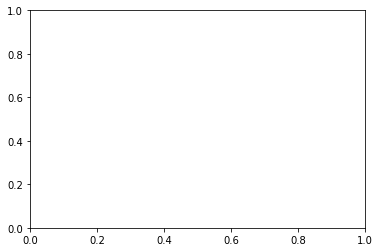

In [ ]:
observation = env.reset()
LEARNING_RATE = 0.00025
NUM_OF_STACKED_FRAMES = 4
TRAINING_THRESHOLD = 50000
EPSILON_DECAY = 0.00012
INITIAL_EPSILON = 1
FINAL_EPSILON = 0.1
DISCOUNT_FACTOR = 0.99
NUM_OF_STEPS_TO_UPDATE = 10000

action_value_function = Model(num_actions=env.action_space.n).to(device)
optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
replay_buffer = ReplayBuffer(50000)
number_of_episodes = 10000
step_counter = 0
episode_scores = []



for ep in range(1, number_of_episodes+1):
    state = env.reset()
    terminated = False
    episode_score = 0
    current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
    visited_states = []
    steps = 0
    while not terminated:
        steps += 1
        previous_state = current_state

        action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

        observation, reward, terminated, info = env.step(action)
        # env.render()
        episode_score += reward
        # reward = max(-1, min(reward, 1))
        
        reward_int = gaussian_novelty_bonus(observation, visited_states)
        #print("Gaussian Intrinsic Reward:",reward_int)
        reward += reward_int

        downsized_observation = downscale_image(observation)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)

        replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
        replay_buffer.update_replay_buffer()    

        visited_states.append(flatten_state(observation))
        if len(visited_states) > MAX_MEMORY:
            visited_states.pop(0)
 
        batch_data = replay_buffer.sample_data(32)


        if replay_buffer.get_length() >= TRAINING_THRESHOLD:
            deep_q_agent.training_step(batch_data)
            del batch_data

    torch.mps.empty_cache()

    deep_q_agent.decrement_epsilon()
    episode_scores.append(episode_score)
    print(f"Episode {ep} has ended in {steps} steps. Agent has scored {episode_score} for this episode")
    print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")


average_scores = []
chunk_size = 100

for i in range(0, len(episode_scores), chunk_size):
    chunk = episode_scores[i:i + chunk_size]
    average_score = sum(chunk) / len(chunk)
    average_scores.append(average_score)

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'trained_uav_agent_newreward.pth')

# Plotting the average scores
# plt.plot(average_scores)
# plt.title("Average Scores per 100 Episodes")
# plt.xlabel("Chunk of 100 Episodes")
# plt.ylabel("Average Score")
# plt.show()

env.close()

<Figure size 2100x1200 with 0 Axes>

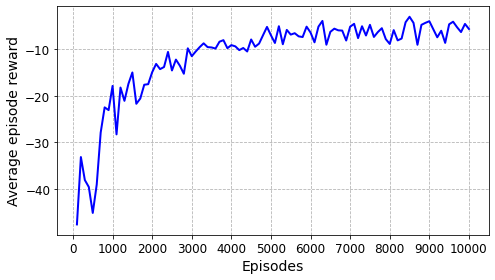

In [36]:
rewards = np.array(average_scores)
# Episodes
episodes = list(range(100, 10001, 100))
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, rewards, color='blue', linewidth=2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(0, 10001, 1000))
plt.tight_layout()
plt.savefig('anchor_training.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
## Load the trained UAV model

init_model = torch.load('trained_uav_agent_newreward.pth')

<ipython-input-8-86bf47f5892a>:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  init_model = torch.load('trained_uav_agent_newreward.pth')


In [9]:
action_value_function = Model(num_actions=4).to(device)
with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
## Disable gradient calculation for shared weights so that they are not updated in the training
c=0
for new_param in action_value_function.parameters():
    c+=1
    if c<9:
        new_param.requires_grad = False
model_parameters = filter(lambda p: p.requires_grad, action_value_function.parameters())
params = sum([np.prod(p.size()) for p in model_parameters])

In [12]:
from torchsummary import summary
summary(action_value_function,(4,50,50))

Layer (type:depth-idx)                   Output Shape              Param #
├─Conv2d: 1-1                            [-1, 32, 11, 11]          (8,224)
├─Conv2d: 1-2                            [-1, 64, 4, 4]            (32,832)
├─Conv2d: 1-3                            [-1, 64, 2, 2]            (36,928)
├─Linear: 1-4                            [-1, 128]                 (32,896)
├─Linear: 1-5                            [-1, 4]                   516
Total params: 111,396
Trainable params: 516
Non-trainable params: 110,880
Total mult-adds (M): 1.70
Input size (MB): 0.04
Forward/backward pass size (MB): 0.04
Params size (MB): 0.42
Estimated Total Size (MB): 0.50


Layer (type:depth-idx)                   Output Shape              Param #
├─Conv2d: 1-1                            [-1, 32, 11, 11]          (8,224)
├─Conv2d: 1-2                            [-1, 64, 4, 4]            (32,832)
├─Conv2d: 1-3                            [-1, 64, 2, 2]            (36,928)
├─Linear: 1-4                            [-1, 128]                 (32,896)
├─Linear: 1-5                            [-1, 4]                   516
Total params: 111,396
Trainable params: 516
Non-trainable params: 110,880
Total mult-adds (M): 1.70
Input size (MB): 0.04
Forward/backward pass size (MB): 0.04
Params size (MB): 0.42
Estimated Total Size (MB): 0.50

In [15]:
action_value_function = Model(num_actions=12).to(device)
summary(action_value_function,(4,50,50))

Layer (type:depth-idx)                   Output Shape              Param #
├─Conv2d: 1-1                            [-1, 32, 11, 11]          8,224
├─Conv2d: 1-2                            [-1, 64, 4, 4]            32,832
├─Conv2d: 1-3                            [-1, 64, 2, 2]            36,928
├─Linear: 1-4                            [-1, 128]                 32,896
├─Linear: 1-5                            [-1, 12]                  1,548
Total params: 112,428
Trainable params: 112,428
Non-trainable params: 0
Total mult-adds (M): 1.70
Input size (MB): 0.04
Forward/backward pass size (MB): 0.04
Params size (MB): 0.43
Estimated Total Size (MB): 0.51


Layer (type:depth-idx)                   Output Shape              Param #
├─Conv2d: 1-1                            [-1, 32, 11, 11]          8,224
├─Conv2d: 1-2                            [-1, 64, 4, 4]            32,832
├─Conv2d: 1-3                            [-1, 64, 2, 2]            36,928
├─Linear: 1-4                            [-1, 128]                 32,896
├─Linear: 1-5                            [-1, 12]                  1,548
Total params: 112,428
Trainable params: 112,428
Non-trainable params: 0
Total mult-adds (M): 1.70
Input size (MB): 0.04
Forward/backward pass size (MB): 0.04
Params size (MB): 0.43
Estimated Total Size (MB): 0.51

In [14]:
episode_scores_runs = []
average_scores_runs = []

for _ in range(5):
    env = Simple_MA_Env_Centralized_UGV(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    ## Load the weights of first four layers from previous model into the new model
    with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
    ## Disable gradient calculation for shared weights so that they are not updated in the training
    c=0
    for new_param in action_value_function.parameters():
        c+=1
        if c<9:
            new_param.requires_grad = False
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs.append(average_scores)

All people found!
Episode 1 has ended. Agent has scored -72.20000000000002 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored -232.60000000000016 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored -9.300000000000002 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored -27.199999999999985 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored -303.29999999999984 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored -5.800000000000001 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored -283.1999999999996 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9 has

<Figure size 2100x1200 with 0 Axes>

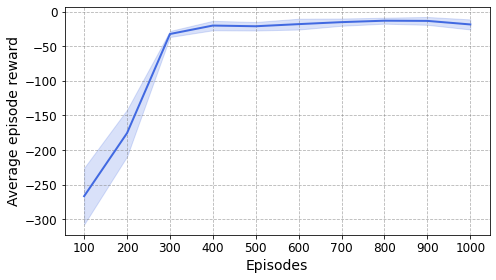

In [15]:
rewards = np.array(average_scores_runs)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='royalblue', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='royalblue', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('finetuning.png', dpi=300, bbox_inches='tight')
plt.show()

In [24]:
# Distributed

episode_scores_runs_distributed = []
average_scores_runs_distributed = []

for _ in range(5):
    env = Simple_MA_Env_Centralized_UGV(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0012
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_distributed.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_distributed.append(average_scores)

All people found!
Episode 1 has ended. Agent has scored -33.69999999999998 for this episode
Current Epsilon value is 0.9988
All people found!
Episode 2 has ended. Agent has scored -25.099999999999977 for this episode
Current Epsilon value is 0.9976
All people found!
Episode 3 has ended. Agent has scored -446.59999999999866 for this episode
Current Epsilon value is 0.9964000000000001
All people found!
Episode 4 has ended. Agent has scored -1172.4999999999995 for this episode
Current Epsilon value is 0.9952000000000001
All people found!
Episode 5 has ended. Agent has scored -50.79999999999997 for this episode
Current Epsilon value is 0.9940000000000001
All people found!
Episode 6 has ended. Agent has scored -474.29999999999876 for this episode
Current Epsilon value is 0.9928000000000001
All people found!
Episode 7 has ended. Agent has scored 1.2 for this episode
Current Epsilon value is 0.9916000000000001
All people found!
Episode 8 has ended. Agent has scored 1 for this episode
Current 

<Figure size 2100x1200 with 0 Axes>

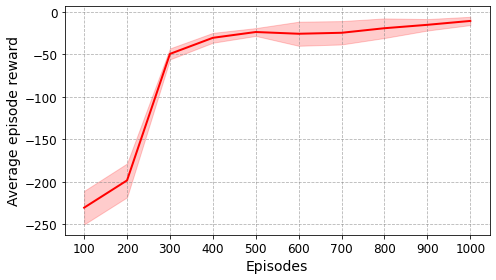

In [12]:
rewards = np.array(average_scores_runs_distributed)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor("#ffffff")  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='red', label='Distributed', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='red', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('distributed_training.png', dpi=300, bbox_inches='tight')
plt.show()

<Figure size 2100x1200 with 0 Axes>

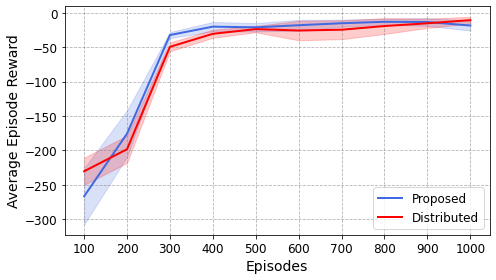

In [16]:
rewards = np.array(average_scores_runs)
rewards_dist = np.array(average_scores_runs_distributed)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)

mean_dist = rewards_dist.mean(axis=0)
std_dist = rewards_dist.std(axis=0)

# Smoothing
# window = 5
# kernel = np.ones(window) / window
# mean_smooth = np.convolve(mean, kernel, mode='same')
# std_smooth = np.convolve(std, kernel, mode='same')

# Episodes
episodes = list(range(100, 1001, 100))

# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
#ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='royalblue', label='Proposed', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='royalblue', alpha=0.2)

ax.plot(episodes, mean_dist, color='red', label='Distributed', linewidth=2)
ax.fill_between(episodes, mean_dist - std_dist, mean_dist + std_dist, 
                color='red', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average Episode Reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
ax.legend(fontsize=12, loc='lower right')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('training_results1.png', dpi=300, bbox_inches='tight')
plt.show()

In [29]:
# Distributed without intrinsic reward

episode_scores_runs_distributed_vanilla = []
average_scores_runs_distributed_vanilla = []

for _ in range(5):
    env = Simple_MA_Env_Centralized_UGV(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0008
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            #reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_distributed_vanilla.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_distributed_vanilla.append(average_scores)

All people found!
Episode 1 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.9992
All people found!
Episode 2 has ended. Agent has scored -15.7 for this episode
Current Epsilon value is 0.9984
All people found!
Episode 3 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.9975999999999999
All people found!
Episode 4 has ended. Agent has scored -230.20000000000022 for this episode
Current Epsilon value is 0.9967999999999999
All people found!
Episode 5 has ended. Agent has scored -26.2 for this episode
Current Epsilon value is 0.9959999999999999
All people found!
Episode 6 has ended. Agent has scored -15.8 for this episode
Current Epsilon value is 0.9951999999999999
All people found!
Episode 7 has ended. Agent has scored -639.5999999999975 for this episode
Current Epsilon value is 0.9943999999999998
All people found!
Episode 8 has ended. Agent has scored -3 for this episode
Current Epsilon value is 0.9935999999999998
All people found!
Episod

<Figure size 2100x1200 with 0 Axes>

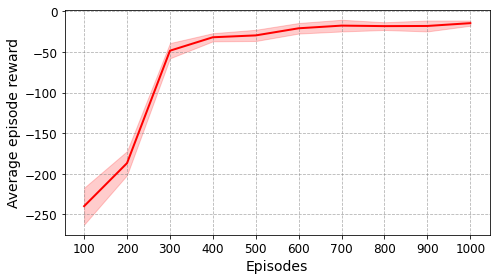

In [20]:
rewards = np.array(average_scores_runs_distributed_vanilla)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)
# Episodes
episodes = list(range(100, 1001, 100))

# mean_smooth = np.convolve(mean, np.ones(3)/3, mode='same')
# std_smooth = np.convolve(std, np.ones(3)/3, mode='same')
# Plot
plt.figure(figsize=(7, 4), dpi=300)
fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor("#ffffff")  # Change overall background color
# ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='red', label='Distributed', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='red', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average episode reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('distributed_training_vanilla.png', dpi=300, bbox_inches='tight')
plt.show()

<Figure size 3000x1800 with 0 Axes>

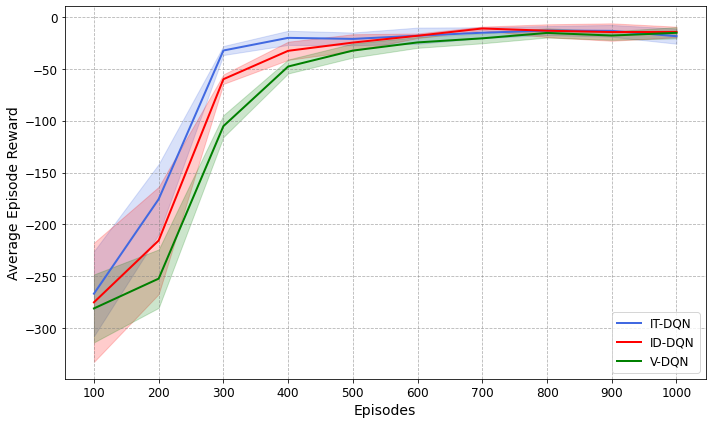

In [51]:
rewards = np.array(average_scores_runs)
rewards_dist = np.array(average_scores_runs_distributed)
rewards_vanilla = np.array(average_scores_runs_distributed_vanilla)
mean = rewards.mean(axis=0)
std = rewards.std(axis=0)

mean_dist = rewards_dist.mean(axis=0)
std_dist = rewards_dist.std(axis=0)

mean_vanilla = rewards_vanilla.mean(axis=0)
std_vanilla = rewards_vanilla.std(axis=0)

# Smoothing
# window = 5
# kernel = np.ones(window) / window
# mean_smooth = np.convolve(mean, kernel, mode='same')
# std_smooth = np.convolve(std, kernel, mode='same')

# Episodes
episodes = list(range(100, 1001, 100))

# Plot
plt.figure(figsize=(10, 6), dpi=300)
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('#ffffff')  # Change overall background color
#ax.set_facecolor('#f0f8ff')         # Change inner plot background

# Plot lines
ax.plot(episodes, mean, color='royalblue', label='IT-DQN', linewidth=2)
ax.fill_between(episodes, mean - std, mean + std, 
                color='royalblue', alpha=0.2)

ax.plot(episodes, mean_dist, color='red', label='ID-DQN', linewidth=2)
ax.fill_between(episodes, mean_dist - std_dist, mean_dist + std_dist, 
                color='red', alpha=0.2)

ax.plot(episodes, mean_vanilla, color='green', label='V-DQN', linewidth=2)
ax.fill_between(episodes, mean_vanilla - std_vanilla, mean_vanilla + std_vanilla, 
                color='green', alpha=0.2)

# Aesthetics
ax.set_xlabel('Episodes', fontsize=14)
ax.set_ylabel('Average Episode Reward', fontsize=14)
#ax.set_title('Training Performance Over Episodes', fontsize=16)
ax.tick_params(axis='both', labelsize=12)
ax.grid(True, linestyle='--', alpha=0.6, color='gray')
ax.legend(fontsize=12, loc='lower right')
plt.xticks(np.arange(min(episodes), max(episodes)+1, 100))
plt.tight_layout()
plt.savefig('training_results2.png', dpi=300, bbox_inches='tight')
plt.show()

In [67]:
episode_scores_runs = []
average_scores_runs = []

for _ in range(1):
    env = Simple_MA_Env_Centralized_UGV(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    ## Load the weights of first four layers from previous model into the new model
    with torch.no_grad(): 
        action_value_function.conv1.load_state_dict(init_model.conv1.state_dict())

        action_value_function.conv2.load_state_dict(init_model.conv2.state_dict())

        action_value_function.conv3.load_state_dict(init_model.conv3.state_dict())

        action_value_function.fc1.load_state_dict(init_model.fc1.state_dict())
    ## Disable gradient calculation for shared weights so that they are not updated in the training
    c=0
    for new_param in action_value_function.parameters():
        c+=1
        if c<9:
            new_param.requires_grad = False
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.002
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs.append(average_scores)

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'trained_ugv_agent_newreward_transferred.pth')

All people found!
Episode 1 has ended. Agent has scored -2047.3000000000216 for this episode
Current Epsilon value is 0.998
All people found!
Episode 2 has ended. Agent has scored -156.60000000000022 for this episode
Current Epsilon value is 0.996
All people found!
Episode 3 has ended. Agent has scored -720.0999999999976 for this episode
Current Epsilon value is 0.994
All people found!
Episode 4 has ended. Agent has scored -900.599999999997 for this episode
Current Epsilon value is 0.992
All people found!
Episode 5 has ended. Agent has scored 1 for this episode
Current Epsilon value is 0.99
All people found!
Episode 6 has ended. Agent has scored -78.50000000000006 for this episode
Current Epsilon value is 0.988
All people found!
Episode 7 has ended. Agent has scored -756.9999999999966 for this episode
Current Epsilon value is 0.986
All people found!
Episode 8 has ended. Agent has scored -427.0999999999995 for this episode
Current Epsilon value is 0.984
All people found!
Episode 9 has e

In [75]:
## Env with both agents (transfer)
from simple_ma_env_uav_ugv_newreward import Simple_MA_Env_Centralized_UAV_UGV
uav_model = torch.load('trained_uav_agent_newreward.pth')
ugv_model = torch.load('trained_ugv_agent_newreward_transferred.pth')
lap_regions_uav = []
lap_regions_ugv = []

all_steps = []
for i in range(100):
    env = Simple_MA_Env_Centralized_UAV_UGV(100)
    obs = env.reset()
    x = random.randrange(int(env.observation_shape[0] * 0.2), int(env.observation_shape[0] * 0.8))
    y = random.randrange(int(env.observation_shape[1] * 0.2), int(env.observation_shape[1] * 0.8))
    env.agents['uav'].set_position(x,y)
    env.agents['ugv'].set_position(x,y)
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    while not done:
        if random.random()>0.2:
            uav_action = torch.argmax(uav_model(current_state.unsqueeze(0))).item()
            ugv_action = torch.argmax(ugv_model(current_state.unsqueeze(0))).item()
        else: 
            uav_action = env.action_space_uav.sample()
            ugv_action = env.action_space_ugv.sample()

        obs,_,_,done,_,lap_region_uav, lap_region_ugv, steps = env.step(uav_action, ugv_action)
        #env.render()

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    all_steps.append(steps)
    lap_regions_uav.append(lap_region_uav)
    lap_regions_ugv.append(lap_region_ugv)

## Unique Coverage Ratio (UCR)
UCR = 0
for i,j in zip(lap_regions_uav, lap_regions_ugv):  
    overlap = i * j
    union = i + j
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
# print("Transfer:",UCR/len(lap_regions_uav))
print("Transfer Average steps:",sum(all_steps)/len(all_steps))

<ipython-input-75-e16f4fe0fe77>:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  uav_model = torch.load('trained_uav_agent_newreward.pth')
<ipython-input-75-e16f4fe0fe77>:4:

Transfer Average steps: 42.64


In [69]:
# Distributed

episode_scores_runs_distributed = []
average_scores_runs_distributed = []

for _ in range(1):
    env = Simple_MA_Env_Centralized_UGV(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0012
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_distributed.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_distributed.append(average_scores)

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'trained_ugv_agent_newreward_distributed.pth')

All people found!
Episode 1 has ended. Agent has scored -14.6 for this episode
Current Epsilon value is 0.9988
All people found!
Episode 2 has ended. Agent has scored -404.8999999999993 for this episode
Current Epsilon value is 0.9976
All people found!
Episode 3 has ended. Agent has scored -311.89999999999975 for this episode
Current Epsilon value is 0.9964000000000001
All people found!
Episode 4 has ended. Agent has scored -91.80000000000007 for this episode
Current Epsilon value is 0.9952000000000001
All people found!
Episode 5 has ended. Agent has scored -138.8000000000001 for this episode
Current Epsilon value is 0.9940000000000001
All people found!
Episode 6 has ended. Agent has scored -25.799999999999983 for this episode
Current Epsilon value is 0.9928000000000001
All people found!
Episode 7 has ended. Agent has scored -108.20000000000005 for this episode
Current Epsilon value is 0.9916000000000001
All people found!
Episode 8 has ended. Agent has scored -468.2999999999993 for thi

In [76]:
## Env with both agents (distributed)
from simple_ma_env_uav_ugv_newreward import Simple_MA_Env_Centralized_UAV_UGV
uav_model = torch.load('trained_uav_agent_newreward.pth')
ugv_model = torch.load('trained_ugv_agent_newreward_distributed.pth')
lap_regions_uav = []
lap_regions_ugv = []

all_steps = []
for i in range(100):
    env = Simple_MA_Env_Centralized_UAV_UGV(100)
    obs = env.reset()
    x = random.randrange(int(env.observation_shape[0] * 0.2), int(env.observation_shape[0] * 0.8))
    y = random.randrange(int(env.observation_shape[1] * 0.2), int(env.observation_shape[1] * 0.8))
    env.agents['uav'].set_position(x,y)
    env.agents['ugv'].set_position(x,y)
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    while not done:
        if random.random()>0.2:
            uav_action = torch.argmax(uav_model(current_state.unsqueeze(0))).item()
            ugv_action = torch.argmax(ugv_model(current_state.unsqueeze(0))).item()
        else: 
            uav_action = env.action_space_uav.sample()
            ugv_action = env.action_space_ugv.sample()

        obs,_,_,done,_,lap_region_uav, lap_region_ugv, steps = env.step(uav_action, ugv_action)
        #env.render()

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    all_steps.append(steps)
    lap_regions_uav.append(lap_region_uav)
    lap_regions_ugv.append(lap_region_ugv)

## Unique Coverage Ratio (UCR)
UCR = 0
for i,j in zip(lap_regions_uav, lap_regions_ugv):  
    overlap = i * j
    union = i + j
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
# print("Distributed:",UCR/len(lap_regions_uav))
print("Distributed Average steps:",sum(all_steps)/len(all_steps))

<ipython-input-76-81b711e40f64>:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  uav_model = torch.load('trained_uav_agent_newreward.pth')
<ipython-input-76-81b711e40f64>:4:

Distributed Average steps: 47.36


In [71]:
# Distributed without intrinsic reward

episode_scores_runs_distributed_vanilla = []
average_scores_runs_distributed_vanilla = []

for _ in range(1):
    env = Simple_MA_Env_Centralized_UGV(100)
    ugv_action_size = 4
    action_value_function = Model(num_actions=ugv_action_size).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=0.00025, momentum=0.95)
    observation = env.reset()
    LEARNING_RATE = 0.00025
    NUM_OF_STACKED_FRAMES = 4
    TRAINING_THRESHOLD = 50000
    EPSILON_DECAY = 0.0008
    INITIAL_EPSILON = 1
    FINAL_EPSILON = 0.1
    DISCOUNT_FACTOR = 0.99
    NUM_OF_STEPS_TO_UPDATE = 10000

    action_value_function = Model(num_actions=env.action_space.n).to(device)
    optimizer = torch.optim.RMSprop(action_value_function.parameters(), lr=LEARNING_RATE, momentum=0.95)
    deep_q_agent = DQNAgent(EPSILON_DECAY, INITIAL_EPSILON, FINAL_EPSILON, DISCOUNT_FACTOR, action_value_function, torch.nn.MSELoss(), optimizer, device)
    replay_buffer = ReplayBuffer(50000)
    ## Set less no. of episodes as the training should not take time due to shared weights
    number_of_episodes = 1000
    step_counter = 0
    episode_scores = []
    for ep in range(1, number_of_episodes+1):
        state = env.reset()
        terminated = False
        episode_score = 0
        current_state = torch.zeros((NUM_OF_STACKED_FRAMES, 50, 50), dtype=torch.float32, device=device)
        steps = 0
        while not terminated:
            steps += 1
            previous_state = current_state

            action = deep_q_agent.select_action(env.action_space.n, current_state.unsqueeze(0))

            observation, reward, terminated, info = env.step(action)
            # env.render()
            episode_score += reward
            # reward = max(-1, min(reward, 1))

            #reward_int = gaussian_novelty_bonus(observation, visited_states)
            #print("Gaussian Intrinsic Reward:",reward_int)
            reward += reward_int

            downsized_observation = downscale_image(observation)
            downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

            current_state = update_frame_stack(current_state, downsized_observation_tensor)

            replay_buffer.insert_data(previous_state, action, torch.tensor(reward).to(dtype=torch.float32), current_state, terminated)
            replay_buffer.update_replay_buffer()
    
            batch_data = replay_buffer.sample_data(32)


            if replay_buffer.get_length() >= TRAINING_THRESHOLD:
                deep_q_agent.training_step(batch_data)
                del batch_data

        torch.mps.empty_cache()

        deep_q_agent.decrement_epsilon()
        episode_scores.append(episode_score)
        print(f"Episode {ep} has ended. Agent has scored {episode_score} for this episode")
        print(f"Current Epsilon value is {deep_q_agent.get_epsilon()}")
    episode_scores_runs_distributed_vanilla.append(episode_scores)


    average_scores = []
    chunk_size = 100

    for i in range(0, len(episode_scores), chunk_size):
        chunk = episode_scores[i:i + chunk_size]
        average_score = sum(chunk) / len(chunk)
        average_scores.append(average_score)
    average_scores_runs_distributed_vanilla.append(average_scores)

final_model = deep_q_agent.get_final_model()
torch.save(final_model, 'trained_ugv_agent_newreward_vanilla.pth')

All people found!
Episode 1 has ended. Agent has scored -10.9 for this episode
Current Epsilon value is 0.9992
All people found!
Episode 2 has ended. Agent has scored -360.8999999999994 for this episode
Current Epsilon value is 0.9984
All people found!
Episode 3 has ended. Agent has scored -128.0000000000002 for this episode
Current Epsilon value is 0.9975999999999999
All people found!
Episode 4 has ended. Agent has scored -560.3999999999978 for this episode
Current Epsilon value is 0.9967999999999999
All people found!
Episode 5 has ended. Agent has scored -558.5999999999982 for this episode
Current Epsilon value is 0.9959999999999999
All people found!
Episode 6 has ended. Agent has scored -275.09999999999997 for this episode
Current Epsilon value is 0.9951999999999999
All people found!
Episode 7 has ended. Agent has scored -32.39999999999999 for this episode
Current Epsilon value is 0.9943999999999998
All people found!
Episode 8 has ended. Agent has scored -357.29999999999944 for this

In [79]:
## Env with both agents (distributed)
from simple_ma_env_uav_ugv_newreward import Simple_MA_Env_Centralized_UAV_UGV
uav_model = torch.load('trained_uav_agent_newreward.pth')
ugv_model = torch.load('trained_ugv_agent_newreward_vanilla.pth')
lap_regions_uav = []
lap_regions_ugv = []

all_steps = []
for i in range(100):
    env = Simple_MA_Env_Centralized_UAV_UGV(100)
    obs = env.reset()
    x = random.randrange(int(env.observation_shape[0] * 0.2), int(env.observation_shape[0] * 0.8))
    y = random.randrange(int(env.observation_shape[1] * 0.2), int(env.observation_shape[1] * 0.8))
    env.agents['uav'].set_position(x,y)
    env.agents['ugv'].set_position(x,y)
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    while not done:
        if random.random()>0.2:
            uav_action = torch.argmax(uav_model(current_state.unsqueeze(0))).item()
            ugv_action = torch.argmax(ugv_model(current_state.unsqueeze(0))).item()
        else: 
            uav_action = env.action_space_uav.sample()
            ugv_action = env.action_space_ugv.sample()

        obs,_,_,done,_,lap_region_uav, lap_region_ugv, steps = env.step(uav_action, ugv_action)
        # env.render()

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    all_steps.append(steps)
    lap_regions_uav.append(lap_region_uav)
    lap_regions_ugv.append(lap_region_ugv)

## Unique Coverage Ratio (UCR)
UCR = 0
for i,j in zip(lap_regions_uav, lap_regions_ugv):  
    overlap = i * j
    union = i + j
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
print("Vanilla:",UCR/len(lap_regions_uav))

<ipython-input-79-26ce96c22364>:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  uav_model = torch.load('trained_uav_agent_newreward.pth')
<ipython-input-79-26ce96c22364>:4:

Vanilla Average steps: 46.81


In [73]:
## Random Search
from simple_ma_env_uav_ugv_newreward import Simple_MA_Env_Centralized_UAV_UGV
lap_regions_uav = []
lap_regions_ugv = []

all_steps = []
for i in range(100):
    env = Simple_MA_Env_Centralized_UAV_UGV(100)
    obs = env.reset()
    x = random.randrange(int(env.observation_shape[0] * 0.2), int(env.observation_shape[0] * 0.8))
    y = random.randrange(int(env.observation_shape[1] * 0.2), int(env.observation_shape[1] * 0.8))
    env.agents['uav'].set_position(x,y)
    env.agents['ugv'].set_position(x,y)
    current_state = torch.zeros((4, 50, 50), dtype=torch.float32, device=device)
    done = False
    while not done:
        uav_action = env.action_space_uav.sample()
        ugv_action = env.action_space_ugv.sample()

        obs,_,_,done,_,lap_region_uav, lap_region_ugv, steps = env.step(uav_action, ugv_action)
        env.render()

        downsized_observation = downscale_image(obs)
        downsized_observation_tensor = torch.tensor(downsized_observation, dtype=torch.float32, device=device)

        current_state = update_frame_stack(current_state, downsized_observation_tensor)
        # print(uav_action, ugv_action)
        # uav_action = env.action_space_uav.sample()
        # ugv_action = env.action_space_ugv.sample()
    all_steps.append(steps)
    lap_regions_uav.append(lap_region_uav)
    lap_regions_ugv.append(lap_region_ugv)

## Unique Coverage Ratio (UCR)
UCR = 0
for i,j in zip(lap_regions_uav, lap_regions_ugv):  
    overlap = i * j
    union = i + j
    unique = np.count_nonzero(union) - np.count_nonzero(overlap)
    ucr = unique/np.count_nonzero(union)
    UCR += ucr
print("Random:",UCR/len(lap_regions_uav))

Random: 0.8912350526071379


In [ ]:
print("Random Average Steps:",sum(all_steps)/len(all_steps))

331.01